# 1. Contexte métier et problématique

## 1.1 Contexte

TouNum est une entreprise spécialisée dans la numérisation de documents, notamment à partir de supports papier. Dans le cadre de l'augmentation du volume de documents numérisés, l'entreprise souhaite développer de nouveaux services reposant sur les techniques de Machine Learning.

L'un des objectifs du projet consiste à mettre en place une chaîne automatisée permettant d'analyser des images et, à terme, de générer automatiquement une légende descriptive de leur contenu.

Avant de réaliser cette étape de génération de légendes (*image captioning*), une étape de filtrage est nécessaire. En effet, l'ensemble des images numérisées par TouNum ne correspond pas nécessairement à des photographies. Le dataset peut également contenir des schémas, des graphiques, des textes scannés, des dessins ou encore des peintures.

L'objectif de ce premier livrable est donc de développer un modèle de classification capable de distinguer automatiquement :

* les **photographies** ;
* les **autres types d'images**.

Cette classification permettra de sélectionner automatiquement les photographies qui pourront ensuite être transmises aux étapes suivantes du workflow.

## 1.2 Problématique

La problématique étudiée dans ce livrable est donc la suivante :

**Comment développer un modèle de réseau de neurones capable de distinguer automatiquement une photographie d'une autre catégorie d'image dans un ensemble de documents numérisés ?**

La difficulté du problème dépend notamment de la nature des images à distinguer. Les textes scannés ou les schémas présentent généralement des caractéristiques visuelles très différentes des photographies. À l'inverse, certaines peintures possèdent un rendu très réaliste et peuvent donc être visuellement proches d'une photographie.

L'objectif sera ainsi de construire progressivement un modèle, d'évaluer ses performances et d'analyser ses limites afin de déterminer s'il est suffisamment pertinent pour être intégré au workflow de TouNum.


# 2. Objectif de la classification

Le problème est formulé comme une **classification binaire supervisée**.

Deux classes sont retenues :

| Classe | Signification | Exemples                                          |
| ------ | ------------- | ------------------------------------------------- |
| `0`    | Autre         | Schéma, graphique, texte scanné, dessin, peinture |
| `1`    | Photo         | Photographie                                      |

Les datasets fournis par TouNum sont initialement répartis dans différents répertoires selon leur nature. L'absence d'étiquette explicite dans les fichiers ne constitue donc pas un problème : la classe pourra être automatiquement déterminée à partir du répertoire dans lequel se trouve chaque image.

L'objectif final est d'obtenir un modèle capable de prendre une image en entrée et de produire une prédiction binaire :

**Image → Réseau de neurones → Photo / Autre**

Cette première classification constitue une étape de filtrage. Les images identifiées comme des photographies pourront ensuite être transmises aux étapes de traitement d'image et de génération automatique de légendes.


## 3. Importation des librairies

In [1]:
import os
import pathlib
import numpy as np
import matplotlib.pyplot as plt
import pathlib

In [2]:
os.environ['KERAS_BACKEND'] = 'torch'
import keras
from keras import layers
import tensorflow as tf

I0000 00:00:1791185956.367604   18352 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791185956.443684   18352 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1791185958.561213   18352 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791185958.562723   18352 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will 

In [3]:
#pour pouvoir entraîner avec le gpu
print("Active backend:", keras.backend.backend())

Active backend: torch


In [4]:
import torch.cuda as cuda

print(cuda.is_available())
if cuda.is_available():
    print(cuda.get_device_name(0))

True
NVIDIA GeForce RTX 5070 Laptop GPU


## 4. Exploration et visualisation des données du dataset

Commençons tout d'abord par explorer les classes du dataset.


In [5]:
datasets_dir = pathlib.Path('datasets') #D:/datasets

In [6]:
invalid_files = []

for file_path in datasets_dir.rglob("*"):
    if file_path.is_file():
        try:
            content = tf.io.read_file(str(file_path))
            _ = tf.io.decode_image(content, expand_animations=False)
        except tf.errors.InvalidArgumentError as e:
            print(f"Fichier corrompu trouvé : {file_path}")
            print(f"Erreur : {e}\n")
            invalid_files.append((file_path, e))

print(f"{len(invalid_files)} fichier(s) invalide(s)")

for file_path, error in invalid_files:
    print(file_path, "->", error)

W0000 00:00:1791185959.524030   18352 gpu_device.cc:2365] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...
Corrupt JPEG data: 419 extraneous bytes before marker 0xd9
W0000 00:00:1791186030.905001   18352 png_io.cc:96] PNG warning: iCCP: known incorrect sRGB profile


0 fichier(s) invalide(s)


In [7]:
for invalid_file in invalid_files:
    invalid_file[0].unlink()

In [8]:
batch_size, img_height, img_width, epochs = 32, 128, 128, 10

In [9]:
def build_datasets(data_dir, batch_size, img_size):
    seed_value = 42

    train_ds = keras.utils.image_dataset_from_directory(
        directory=data_dir,
        validation_split=0.3,
        subset="training",
        seed=seed_value,
        image_size=img_size,
        batch_size=batch_size,
    )

    val_and_test_ds = keras.utils.image_dataset_from_directory(
        directory=data_dir,
        validation_split=0.3,
        subset="validation",
        seed=seed_value,
        image_size=img_size,
        batch_size=batch_size,
    )

    num_eval_batches = tf.data.experimental.cardinality(val_and_test_ds).numpy()
    val_batches = num_eval_batches // 2

    val_ds = val_and_test_ds.take(val_batches)
    test_ds = val_and_test_ds.skip(val_batches)

    return train_ds, val_ds, test_ds

train_ds, val_ds, test_ds = build_datasets(datasets_dir, batch_size=batch_size, img_size=(img_height, img_width))

Found 34096 files belonging to 5 classes.
Using 23868 files for training.
Found 34096 files belonging to 5 classes.
Using 10228 files for validation.


In [10]:
labels = train_ds.class_names

class_distribution = {
    label: sum(1 for file in (datasets_dir / label).iterdir() if file.is_file())
    for label in labels
}

print(class_distribution)

{'Painting': 8172, 'Photo': 8173, 'Schematics': 8172, 'Sketch': 1406, 'Text': 8173}


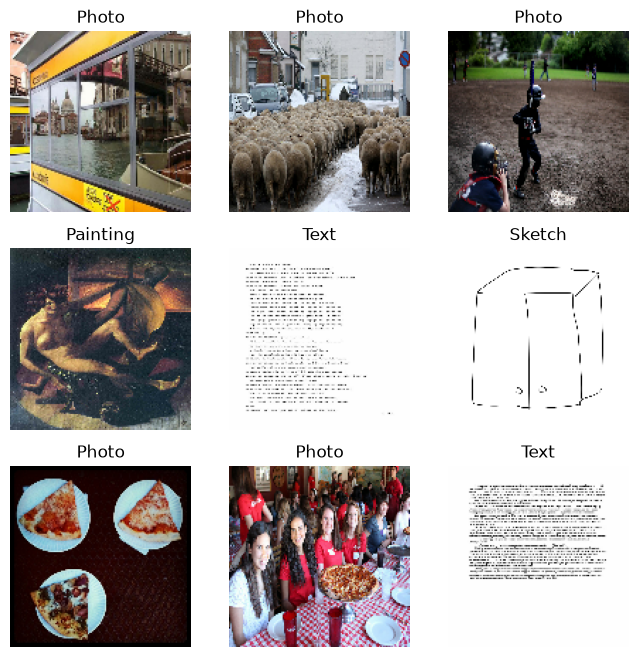

In [11]:
plt.figure(figsize=(8, 8))
for images, label in train_ds.take(1):
    for i in range(9):
        ax = plt.subplot(3, 3, i +1)
        ax.imshow(images[i].numpy().astype('uint8'))
        plt.title(labels[label[i]])
        plt.axis("off")

## Chargement des données dans le cache pour optimiser l'entraînement

In [12]:
def cast_to_uint8(images, labels):
    images = tf.cast(images, tf.uint8)
    return images, labels

In [13]:
AUTOTUNE = tf.data.experimental.AUTOTUNE

train_data = train_ds.map(cast_to_uint8, num_parallel_calls=tf.data.AUTOTUNE).cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)
val_data = val_ds.map(cast_to_uint8, num_parallel_calls=tf.data.AUTOTUNE).cache().prefetch(buffer_size=AUTOTUNE)
test_data = test_ds.map(cast_to_uint8, num_parallel_calls=tf.data.AUTOTUNE).cache().prefetch(buffer_size=AUTOTUNE)

In [14]:
import psutil
from tqdm import tqdm

process = psutil.Process(os.getpid())

def preload_and_cache(dataset, total_batches, split_name="Dataset"):
    initial_ram = process.memory_info().rss / (1024 ** 2)
    print(f"\n--- Caching {split_name} (RAM before: {initial_ram:.1f} MB) ---")
    
    for _ in tqdm(dataset, total=total_batches, desc=f"Loading {split_name}", unit="batch"):
        pass

    final_ram = process.memory_info().rss / (1024 ** 2)
    delta_ram = final_ram - initial_ram
    print(f"{split_name} cached. RAM used: {final_ram:.1f} MB (+{delta_ram:.1f} MB added)")

preload_and_cache(train_data, len(train_ds), "Train")
preload_and_cache(val_data, len(val_ds), "Validation")
preload_and_cache(test_data, len(test_ds), "Test")


--- Caching Train (RAM before: 1717.4 MB) ---


Loading Train:   0%|          | 0/746 [00:00<?, ?batch/s]Corrupt JPEG data: 419 extraneous bytes before marker 0xd9
W0000 00:00:1791186063.419205   19061 png_io.cc:96] PNG warning: iCCP: known incorrect sRGB profile
Loading Train: 100%|██████████| 746/746 [00:06<00:00, 121.44batch/s]


Train cached. RAM used: 3800.3 MB (+2082.9 MB added)

--- Caching Validation (RAM before: 3800.3 MB) ---


Loading Validation: 100%|██████████| 160/160 [00:01<00:00, 95.24batch/s] 


Validation cached. RAM used: 4516.6 MB (+716.3 MB added)

--- Caching Test (RAM before: 4516.6 MB) ---


Loading Test: 100%|██████████| 160/160 [00:02<00:00, 61.51batch/s] 

Test cached. RAM used: 5063.5 MB (+546.9 MB added)


## Construction du modèle CNN

Un réseau de neurones convolutif (CNN) est utilisé car il est particulièrement adapté à l'analyse d'images.

Les couches de convolution permettent d'extraire progressivement des caractéristiques visuelles :
- contours ;
- textures ;
- formes ;
- motifs plus complexes.

Les couches de MaxPooling réduisent progressivement la résolution spatiale des représentations tout en conservant les informations les plus importantes.

Une couche Flatten transforme ensuite la représentation multidimensionnelle en vecteur afin de pouvoir utiliser des couches denses pour la classification.

La dernière couche contient un seul neurone associé à une fonction d'activation sigmoïde. Elle produit une probabilité comprise entre 0 et 1 correspondant à la probabilité que l'image appartienne à la classe « Photo ».

In [15]:
model_baseline = keras.Sequential([

    layers.Input(shape=(img_height, img_width, 3)),
    layers.Rescaling(1./255),
    layers.Conv2D(32, (3, 3),activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64,(3, 3),activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(128,(3, 3),activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dense(len(labels), activation="softmax")
])

model_baseline.summary()

model_baseline.compile(optimizer="adam", loss ='sparse_categorical_crossentropy', metrics=['accuracy'])

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,305,285 (12.61 MB)

 Trainable params: 3,305,285 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

In [16]:
history_baseline = model_baseline.fit(
    train_data,
    validation_data=val_data,
    epochs=epochs,
    batch_size=batch_size,
)

Epoch 1/10


/home/jxc/school/cesi/Leyenda/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


746/746 ━━━━━━━━━━━━━━━━━━━━ 12s 16ms/step - accuracy: 0.7673 - loss: 0.5460 - val_accuracy: 0.8295 - val_loss: 0.4261
Epoch 2/10
746/746 ━━━━━━━━━━━━━━━━━━━━ 12s 16ms/step - accuracy: 0.8625 - loss: 0.3448 - val_accuracy: 0.8736 - val_loss: 0.3071
Epoch 3/10
746/746 ━━━━━━━━━━━━━━━━━━━━ 10s 14ms/step - accuracy: 0.8935 - loss: 0.2655 - val_accuracy: 0.8873 - val_loss: 0.2921
Epoch 4/10
746/746 ━━━━━━━━━━━━━━━━━━━━ 12s 16ms/step - accuracy: 0.9187 - loss: 0.2049 - val_accuracy: 0.8803 - val_loss: 0.3054
Epoch 5/10
746/746 ━━━━━━━━━━━━━━━━━━━━ 12s 16ms/step - accuracy: 0.9401 - loss: 0.1575 - val_accuracy: 0.8813 - val_loss: 0.3273
Epoch 6/10
746/746 ━━━━━━━━━━━━━━━━━━━━ 10s 14ms/step - accuracy: 0.9598 - loss: 0.1103 - val_accuracy: 0.8803 - val_loss: 0.3826
Epoch 7/10
746/746 ━━━━━━━━━━━━━━━━━━━━ 12s 16ms/step - accuracy: 0.9690 - loss: 0.0859 - val_accuracy: 0.8848 - val_loss: 0.4627
Epoch 8/10
746/746 ━━━━━━━━━━━━━━━━━━━━ 11s 14ms/step - accuracy: 0.9797 - loss: 0.0599 - val_accurac

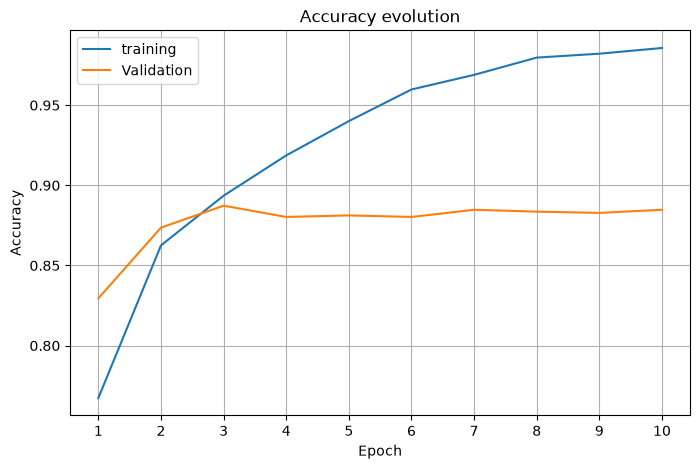

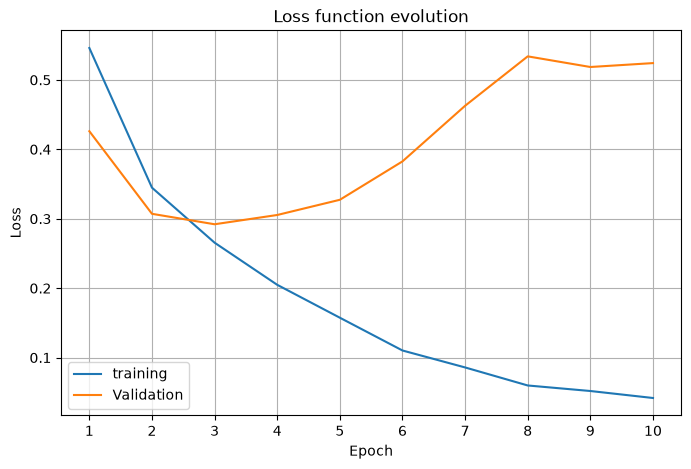

In [17]:
acc = history_baseline.history["accuracy"]
val_acc = history_baseline.history["val_accuracy"]
loss = history_baseline.history["loss"]
val_loss = history_baseline.history["val_loss"]
actual_epochs = range(1, epochs + 1)

# accuracy plots
plt.figure(figsize=(8, 5))
plt.plot(actual_epochs, acc, label="training")
plt.plot(actual_epochs, val_acc, label="Validation")
plt.title("Accuracy evolution")
plt.xticks(actual_epochs)
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

# loss plots
plt.figure(figsize=(8, 5))
plt.plot(actual_epochs, loss, label="training")
plt.plot(actual_epochs, val_loss, label="Validation")
plt.title("Loss function evolution")
plt.xticks(actual_epochs)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

In [18]:
print(f'final training loss: {loss[-1]}\nfinal validation loss: {val_loss[-1]}')
print(f'--- generalization gap: {abs(loss[-1] - val_loss[-1])} ---')
print(f'\nfinal training accuracy: {acc[-1]}\nfinal validation accuracy: {val_acc[-1]}')
print(f'--- accuracy gap: {abs(acc[-1] - val_acc[-1])} ---')

final training loss: 0.04184381663799286
final validation loss: 0.5242124795913696
--- generalization gap: 0.48236866295337677 ---

final training accuracy: 0.9857130646705627
final validation accuracy: 0.884765625
--- accuracy gap: 0.10094743967056274 ---


In [19]:
model_baseline.save('model_baseline.weights.h5')

On peut voir que le modèle est en surapprentissage, nous allons tester différentes techniques pour réduire l'erreur de généralisation

## Data augmentation sur la classe Sketch

La classe `Sketch` est largement minoritaire dans le dataset (environ 1 400 images contre plus de 8 000 pour les autres classes). Le modèle baseline voit donc très peu de croquis pendant l'entraînement : il a tendance à les confondre avec d'autres classes et à mémoriser les quelques exemples disponibles.

Pour compenser ce déséquilibre, nous appliquons une **data augmentation ciblée** : uniquement les images `Sketch` du jeu d'entraînement sont dupliquées puis transformées aléatoirement (retournement, rotation, zoom, translation, contraste). Les autres classes restent inchangées, tout comme les jeux de validation et de test, afin que l'évaluation reste comparable à celle du baseline.

L'architecture du modèle est strictement identique à celle du baseline : seule la composition du jeu d'entraînement change.

classe       precision    recall        f1   support
Painting         0.785     0.810     0.797      1206
Photo            0.829     0.799     0.814      1197
Schematics       0.930     0.913     0.921      1258
Sketch           0.880     0.995     0.934       199
Text             0.998     0.999     0.999      1248

accuracy globale : 0.8863


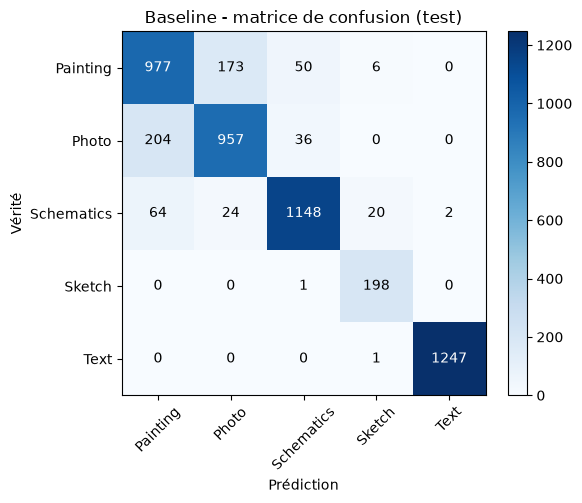

In [20]:
def per_class_metrics(model, dataset):
    y_true, y_pred = [], []
    for images, batch_labels in dataset:
        probs = model.predict_on_batch(images)
        y_true.append(np.asarray(batch_labels))
        y_pred.append(np.argmax(np.asarray(probs), axis=1))
    y_true, y_pred = np.concatenate(y_true), np.concatenate(y_pred)

    confusion = np.zeros((len(labels), len(labels)), dtype=int)
    for t, p in zip(y_true, y_pred):
        confusion[t, p] += 1

    print(f"{'classe':<12}{'precision':>10}{'recall':>10}{'f1':>10}{'support':>10}")
    for i, label in enumerate(labels):
        tp = confusion[i, i]
        precision = tp / max(confusion[:, i].sum(), 1)
        recall = tp / max(confusion[i, :].sum(), 1)
        f1 = 2 * precision * recall / max(precision + recall, 1e-9)
        print(f"{label:<12}{precision:>10.3f}{recall:>10.3f}{f1:>10.3f}{confusion[i, :].sum():>10}")
    print(f"\naccuracy globale : {np.trace(confusion) / confusion.sum():.4f}")

    return confusion

def plot_confusion(confusion, title):
    plt.figure(figsize=(6, 5))
    plt.imshow(confusion, cmap="Blues")
    plt.title(title)
    plt.xticks(range(len(labels)), labels, rotation=45)
    plt.yticks(range(len(labels)), labels)
    plt.xlabel("Prédiction")
    plt.ylabel("Vérité")
    for i in range(len(labels)):
        for j in range(len(labels)):
            plt.text(j, i, confusion[i, j], ha="center", va="center",
                     color="white" if confusion[i, j] > confusion.max() / 2 else "black")
    plt.colorbar()
    plt.tight_layout()
    plt.show()

confusion_baseline = per_class_metrics(model_baseline, test_data)
plot_confusion(confusion_baseline, "Baseline - matrice de confusion (test)")

In [21]:
sketch_index = labels.index("Sketch")

# fond blanc pour les zones créées par rotation / zoom / translation (les croquis sont sur fond clair)
sketch_augmentation = [
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05, fill_mode="constant", fill_value=255.0),
    layers.RandomZoom(0.1, fill_mode="constant", fill_value=255.0),
    layers.RandomTranslation(0.1, 0.1, fill_mode="constant", fill_value=255.0),
    layers.RandomContrast(0.2, value_range=(0, 255)),
]

# les couches sont appelées une par une : un keras.Sequential ne peut pas être utilisé dans tf.data avec le backend torch
def augment_sketch(image, label):
    image = tf.cast(image, tf.float32)
    for layer in sketch_augmentation:
        image = layer(image, training=True)
    return image, label

def to_float32(image, label):
    return tf.cast(image, tf.float32), label

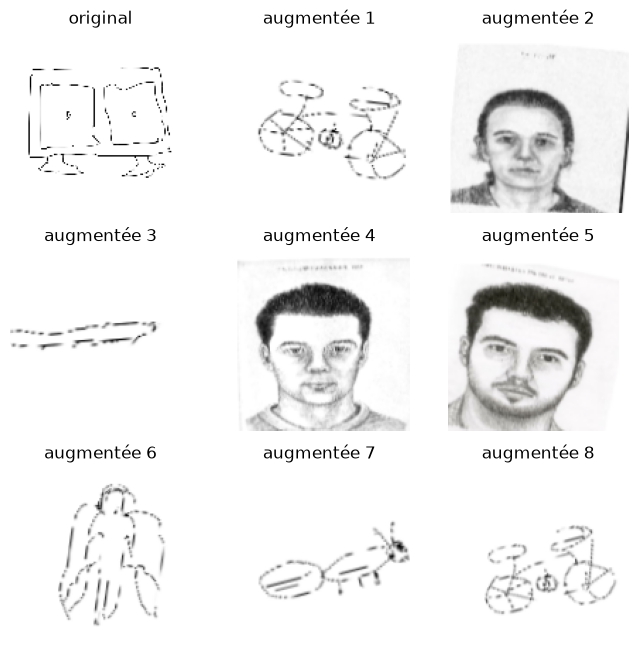

In [22]:
sketch_sample = train_data.unbatch().filter(lambda image, label: tf.equal(label, sketch_index)).take(1)
augmented_samples = sketch_sample.repeat(8).map(augment_sketch)

plt.figure(figsize=(8, 8))
for i, (image, _) in enumerate(sketch_sample.concatenate(augmented_samples.map(lambda image, label: (tf.cast(image, tf.uint8), label)))):
    ax = plt.subplot(3, 3, i + 1)
    ax.imshow(image.numpy())
    plt.title("original" if i == 0 else f"augmentée {i}")
    plt.axis("off")

In [23]:
train_label_counts = np.bincount(
    np.concatenate([np.asarray(batch_labels) for _, batch_labels in train_data]),
    minlength=len(labels),
)
print(dict(zip(labels, train_label_counts)))

n_sketch = train_label_counts[sketch_index]
n_others = train_label_counts.sum() - n_sketch
mean_other_class = n_others / (len(labels) - 1)

# nombre de copies augmentées par croquis pour atteindre la taille moyenne des autres classes
augmentation_factor = max(int(round(mean_other_class / n_sketch)) - 1, 1)
n_sketch_total = n_sketch * (1 + augmentation_factor)
print(f"facteur d'augmentation : {augmentation_factor} -> {n_sketch_total} images Sketch par epoch")

train_unbatched = train_data.unbatch()

sketch_original = train_unbatched.filter(lambda image, label: tf.equal(label, sketch_index)).map(to_float32)
sketch_augmented = (
    train_unbatched.filter(lambda image, label: tf.equal(label, sketch_index))
    .repeat(augmentation_factor)
    .map(augment_sketch, num_parallel_calls=AUTOTUNE)
)
sketch_ds = sketch_original.concatenate(sketch_augmented).shuffle(2000)
others_ds = train_unbatched.filter(lambda image, label: tf.not_equal(label, sketch_index)).map(to_float32)

train_data_aug = (
    tf.data.Dataset.sample_from_datasets(
        [others_ds, sketch_ds],
        weights=[n_others / (n_others + n_sketch_total), n_sketch_total / (n_others + n_sketch_total)],
    )
    .batch(batch_size)
    .prefetch(buffer_size=AUTOTUNE)
)

{'Painting': np.int64(5714), 'Photo': np.int64(5732), 'Schematics': np.int64(5695), 'Sketch': np.int64(1003), 'Text': np.int64(5724)}
facteur d'augmentation : 5 -> 6018 images Sketch par epoch


In [24]:
model_sketch_aug = keras.models.clone_model(model_baseline)  # même architecture, poids réinitialisés

model_sketch_aug.compile(optimizer="adam", loss='sparse_categorical_crossentropy', metrics=['accuracy'])

history_sketch_aug = model_sketch_aug.fit(
    train_data_aug,
    validation_data=val_data,
    epochs=epochs,
)

/home/jxc/school/cesi/Leyenda/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


Epoch 1/10
    901/Unknown 21s 18ms/step - accuracy: 0.7900 - loss: 0.4898

/home/jxc/school/cesi/Leyenda/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


903/903 ━━━━━━━━━━━━━━━━━━━━ 22s 19ms/step - accuracy: 0.7904 - loss: 0.4890 - val_accuracy: 0.6078 - val_loss: 1.7392
Epoch 2/10
903/903 ━━━━━━━━━━━━━━━━━━━━ 19s 16ms/step - accuracy: 0.8718 - loss: 0.3193 - val_accuracy: 0.8457 - val_loss: 0.4309
Epoch 3/10
903/903 ━━━━━━━━━━━━━━━━━━━━ 20s 16ms/step - accuracy: 0.9020 - loss: 0.2477 - val_accuracy: 0.8605 - val_loss: 0.3619
Epoch 4/10
903/903 ━━━━━━━━━━━━━━━━━━━━ 22s 18ms/step - accuracy: 0.9276 - loss: 0.1860 - val_accuracy: 0.8768 - val_loss: 0.3312
Epoch 5/10
903/903 ━━━━━━━━━━━━━━━━━━━━ 20s 17ms/step - accuracy: 0.9418 - loss: 0.1503 - val_accuracy: 0.8283 - val_loss: 0.5812
Epoch 6/10
903/903 ━━━━━━━━━━━━━━━━━━━━ 20s 17ms/step - accuracy: 0.9514 - loss: 0.1260 - val_accuracy: 0.8361 - val_loss: 0.5286
Epoch 7/10
903/903 ━━━━━━━━━━━━━━━━━━━━ 22s 19ms/step - accuracy: 0.9719 - loss: 0.0758 - val_accuracy: 0.8191 - val_loss: 0.7469
Epoch 8/10
903/903 ━━━━━━━━━━━━━━━━━━━━ 20s 17ms/step - accuracy: 0.9764 - loss: 0.0654 - val_accurac

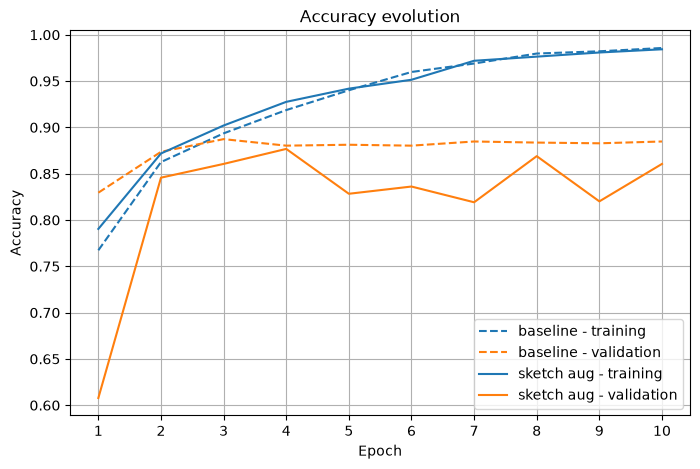

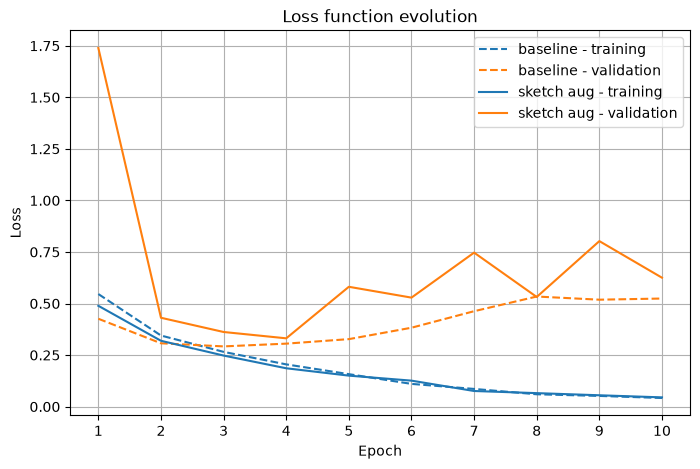

final training loss: 0.044846173375844955
final validation loss: 0.6252215504646301
--- generalization gap: 0.5803753770887852 ---

final training accuracy: 0.9843160510063171
final validation accuracy: 0.860546886920929
--- accuracy gap: 0.12376916408538818 ---


In [25]:
actual_epochs = range(1, epochs + 1)

for metric, title in [("accuracy", "Accuracy evolution"), ("loss", "Loss function evolution")]:
    plt.figure(figsize=(8, 5))
    plt.plot(actual_epochs, history_baseline.history[metric], "--", color="tab:blue", label="baseline - training")
    plt.plot(actual_epochs, history_baseline.history[f"val_{metric}"], "--", color="tab:orange", label="baseline - validation")
    plt.plot(actual_epochs, history_sketch_aug.history[metric], color="tab:blue", label="sketch aug - training")
    plt.plot(actual_epochs, history_sketch_aug.history[f"val_{metric}"], color="tab:orange", label="sketch aug - validation")
    plt.title(title)
    plt.xticks(actual_epochs)
    plt.xlabel("Epoch")
    plt.ylabel(metric.capitalize())
    plt.legend()
    plt.grid(True)
    plt.show()

aug_loss, aug_val_loss = history_sketch_aug.history["loss"], history_sketch_aug.history["val_loss"]
aug_acc, aug_val_acc = history_sketch_aug.history["accuracy"], history_sketch_aug.history["val_accuracy"]
print(f'final training loss: {aug_loss[-1]}\nfinal validation loss: {aug_val_loss[-1]}')
print(f'--- generalization gap: {abs(aug_loss[-1] - aug_val_loss[-1])} ---')
print(f'\nfinal training accuracy: {aug_acc[-1]}\nfinal validation accuracy: {aug_val_acc[-1]}')
print(f'--- accuracy gap: {abs(aug_acc[-1] - aug_val_acc[-1])} ---')

classe       precision    recall        f1   support
Painting         0.814     0.713     0.760      1206
Photo            0.782     0.840     0.810      1197
Schematics       0.921     0.902     0.912      1258
Sketch           0.698     1.000     0.822       199
Text             0.995     0.994     0.995      1248

accuracy globale : 0.8694


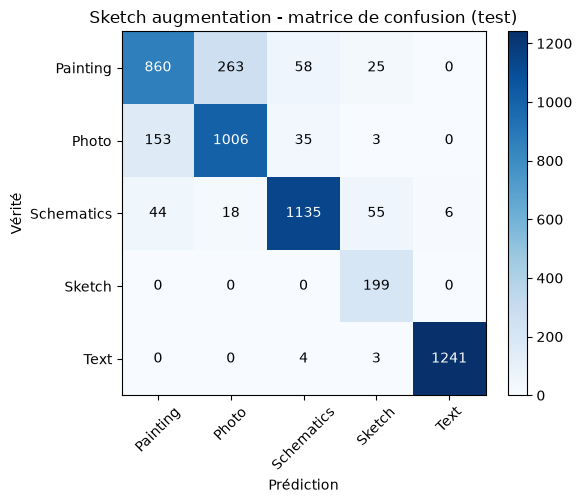

In [26]:
confusion_sketch_aug = per_class_metrics(model_sketch_aug, test_data)
plot_confusion(confusion_sketch_aug, "Sketch augmentation - matrice de confusion (test)")

Pour juger l'effet de l'augmentation, on compare surtout le **recall** et le **F1 de la classe `Sketch`** entre le baseline et ce modèle, ainsi que l'accuracy des autres classes (l'augmentation ne doit pas les dégrader). L'écart entre les courbes d'entraînement et de validation indique si le surapprentissage a diminué.

## Influence de la taille des images

On réentraîne le modèle baseline (même architecture, poids réinitialisés) pour plusieurs tailles d'image entre 128 et 255 pixels, afin de voir si une résolution plus élevée aide à distinguer les classes proches, en particulier `Painting` et `Photo`.

In [27]:
img_sizes = [128, 160, 192, 224, 255]
size_results = {}

# cache sur disque : en 255x255 le dataset ne tient pas en RAM
cache_dir = pathlib.Path('cache')

for size in img_sizes:
    img_height, img_width = size, size
    print(f"\n===== Taille d'image : {img_height}x{img_width} =====")
    (cache_dir / str(size)).mkdir(parents=True, exist_ok=True)
    splits = build_datasets(datasets_dir, batch_size=batch_size, img_size=(img_height, img_width))
    train_s, val_s, test_s = [
        ds.map(cast_to_uint8, num_parallel_calls=AUTOTUNE).cache(str(cache_dir / str(size) / name))
        for ds, name in zip(splits, ["train", "val", "test"])
    ]

    model = keras.models.clone_model(model_baseline, input_tensors=keras.Input(shape=(img_height, img_width, 3)))
    model.compile(optimizer="adam", loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    history = model.fit(train_s.shuffle(1000).prefetch(AUTOTUNE), validation_data=val_s.prefetch(AUTOTUNE), epochs=epochs)

    size_results[size] = {"history": history.history, "confusion": per_class_metrics(model, test_s)}


===== Taille d'image : 128x128 =====
Found 34096 files belonging to 5 classes.
Using 23868 files for training.
Found 34096 files belonging to 5 classes.
Using 10228 files for validation.


/home/jxc/school/cesi/Leyenda/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
Corrupt JPEG data: 419 extraneous bytes before marker 0xd9
W0000 00:00:1791186414.291766   22454 png_io.cc:96] PNG warning: iCCP: known incorrect sRGB profile


Epoch 1/10


W0000 00:00:1791186415.060155   22475 cache_dataset_ops.cc:330] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.
W0000 00:00:1791186415.066161   18352 prefetch_autotuner.cc:55] Prefetch autotuner tried to allocate 1572992 bytes after encountering the first element of size 1572992 bytes.This already causes the autotune ram budget to be exceeded. To stay within the ram budget, either increase the ram budget or reduce element size


746/746 ━━━━━━━━━━━━━━━━━━━━ 16s 18ms/step - accuracy: 0.7578 - loss: 0.5628 - val_accuracy: 0.8311 - val_loss: 0.4313
Epoch 2/10


...

W0000 00:00:1791187417.576920   18352 cache_dataset_ops.cc:330] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.


746/746 ━━━━━━━━━━━━━━━━━━━━ 42s 50ms/step - accuracy: 0.8710 - loss: 0.3244 - val_accuracy: 0.8859 - val_loss: 0.3017
Epoch 3/10
746/746 ━━━━━━━━━━━━━━━━━━━━ 43s 52ms/step - accuracy: 0.9089 - loss: 0.2322 - val_accuracy: 0.8932 - val_loss: 0.3093
Epoch 4/10
746/746 ━━━━━━━━━━━━━━━━━━━━ 42s 51ms/step - accuracy: 0.9410 - loss: 0.1600 - val_accuracy: 0.8791 - val_loss: 0.3601
Epoch 5/10
746/746 ━━━━━━━━━━━━━━━━━━━━ 43s 52ms/step - accuracy: 0.9621 - loss: 0.1096 - val_accuracy: 0.8914 - val_loss: 0.3851
Epoch 6/10
746/746 ━━━━━━━━━━━━━━━━━━━━ 40s 48ms/step - accuracy: 0.9771 - loss: 0.0658 - val_accuracy: 0.8838 - val_loss: 0.4506
Epoch 7/10
746/746 ━━━━━━━━━━━━━━━━━━━━ 43s 52ms/step - accuracy: 0.9828 - loss: 0.0501 - val_accuracy: 0.8559 - val_loss: 0.6348
Epoch 8/10
746/746 ━━━━━━━━━━━━━━━━━━━━ 42s 51ms/step - accuracy: 0.9853 - loss: 0.0494 - val_accuracy: 0.8715 - val_loss: 0.5716
Epoch 9/10
746/746 ━━━━━━━━━━━━━━━━━━━━ 40s 49ms/step - accuracy: 0.9875 - loss: 0.0395 - val_accurac

W0000 00:00:1791187796.162209   18352 prefetch_autotuner.cc:55] Prefetch autotuner tried to allocate 6242528 bytes after encountering the first element of size 6242528 bytes.This already causes the autotune ram budget to be exceeded. To stay within the ram budget, either increase the ram budget or reduce element size


classe       precision    recall        f1   support
Painting         0.761     0.783     0.772      1206
Photo            0.793     0.773     0.783      1197
Schematics       0.926     0.910     0.918      1258
Sketch           0.917     0.995     0.954       199
Text             0.998     0.997     0.997      1248

accuracy globale : 0.8724


W0000 00:00:1791187800.276469   18352 cache_dataset_ops.cc:330] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.


taille     val acc  test acc  photo recall  photo precision  gap loss
128         0.8855    0.8802         0.787            0.820     0.489
160         0.8865    0.8917         0.842            0.818     0.534
192         0.8822    0.8757         0.739            0.840     0.583
224         0.8406    0.8449         0.904            0.681     0.892
255         0.8791    0.8724         0.773            0.793     0.582


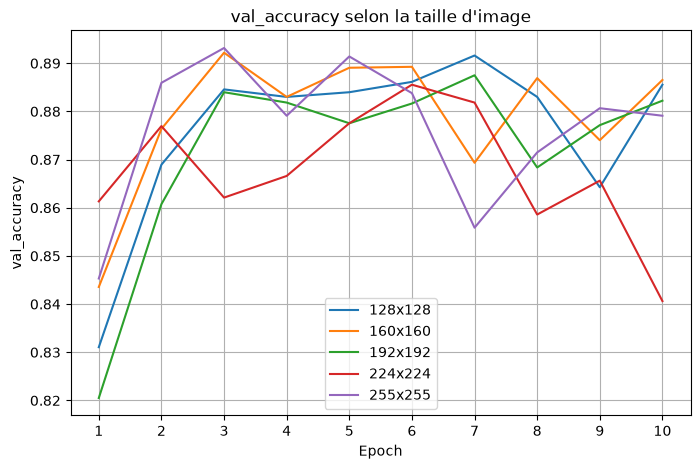

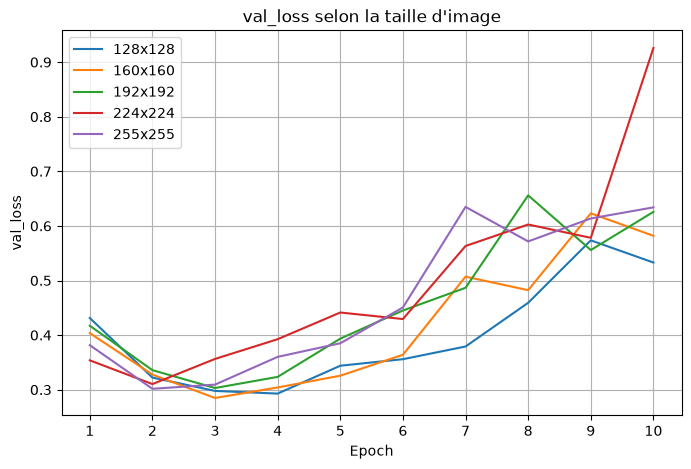

In [28]:
photo_index = labels.index("Photo")

print(f"{'taille':<8}{'val acc':>10}{'test acc':>10}{'photo recall':>14}{'photo precision':>17}{'gap loss':>10}")
for size, result in size_results.items():
    h, c = result["history"], result["confusion"]
    print(f"{size:<8}{h['val_accuracy'][-1]:>10.4f}{np.trace(c) / c.sum():>10.4f}"
          f"{c[photo_index, photo_index] / c[photo_index].sum():>14.3f}"
          f"{c[photo_index, photo_index] / max(c[:, photo_index].sum(), 1):>17.3f}"
          f"{abs(h['loss'][-1] - h['val_loss'][-1]):>10.3f}")

for metric in ["val_accuracy", "val_loss"]:
    plt.figure(figsize=(8, 5))
    for size, result in size_results.items():
        plt.plot(range(1, epochs + 1), result["history"][metric], label=f"{size}x{size}")
    plt.title(f"{metric} selon la taille d'image")
    plt.xticks(range(1, epochs + 1))
    plt.xlabel("Epoch")
    plt.ylabel(metric)
    plt.legend()
    plt.grid(True)
    plt.show()